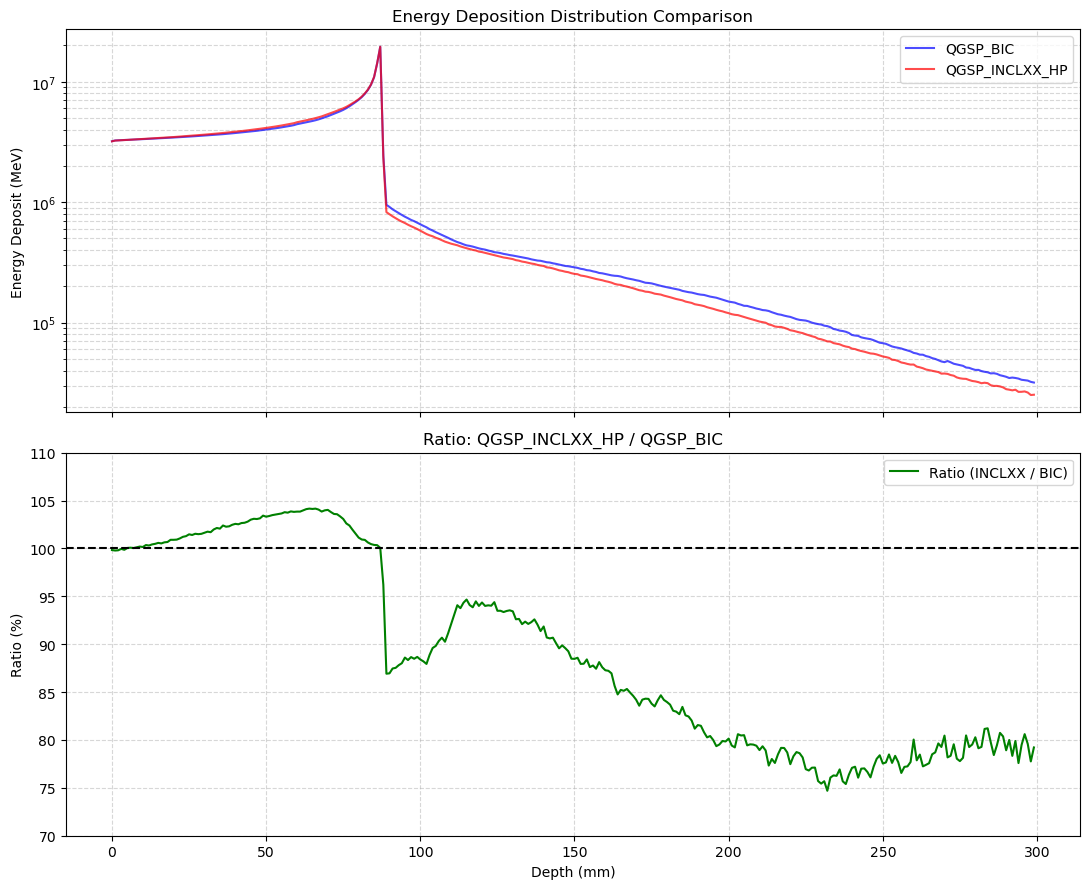

Average Ratio (0-80mm): 102.16%
Ratio at Bragg Peak (87mm): 100.06%
Average Ratio (90-300mm): 83.39%


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# データの読み込み
df_bic = pd.read_csv('carbon2400_QGSP_BIC.csv').sort_values('copyNo')
df_incl = pd.read_csv('carbon2400_QGSP_INCLXX_HP.csv').sort_values('copyNo')

# 深度(mm)と比率(%)の計算
depth = df_bic['copyNo']
ratio_percent = (df_incl['total_energy'] / df_bic['total_energy']) * 100

# プロット作成
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

# 上段: エネルギー分布の比較（対数軸）
ax1.plot(depth, df_bic['total_energy'], label='QGSP_BIC', color='blue', alpha=0.7)
ax1.plot(depth, df_incl['total_energy'], label='QGSP_INCLXX_HP', color='red', alpha=0.7)
ax1.set_yscale('log')
ax1.set_ylabel('Energy Deposit (MeV)')
ax1.set_title('Energy Deposition Distribution Comparison')
ax1.legend()
ax1.grid(True, which='both', linestyle='--', alpha=0.5)

# 下段: 比率の分布（パーセント）
ax2.plot(depth, ratio_percent, color='green', label='Ratio (INCLXX / BIC)')
ax2.axhline(100, color='black', linestyle='--') # 100%ライン
ax2.set_xlabel('Depth (mm)')
ax2.set_ylabel('Ratio (%)')
ax2.set_title('Ratio: QGSP_INCLXX_HP / QGSP_BIC')
ax2.set_ylim(70, 110) # 変化を見やすく設定
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

# 統計サマリ
print(f"Average Ratio (0-80mm): {ratio_percent[depth < 80].mean():.2f}%")
print(f"Ratio at Bragg Peak (87mm): {ratio_percent[depth == 87].values[0]:.2f}%")
print(f"Average Ratio (90-300mm): {ratio_percent[depth > 90].mean():.2f}%")